# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 6: Fuzzy IF–THEN Rules and Decision Making**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create simple Fuzzy IF–THEN rules for making decisions based on given input conditions.

### 2. Theory: Structure and Evaluation of Fuzzy IF–THEN Rules

Fuzzy IF–THEN rules represent conditional statements that capture human domain expertise in an interpretable format:
$$\text{IF } x \text{ is } A \text{ THEN } y \text{ is } B$$
where:
- $x$ and $y$ are linguistic variables.
- $A$ and $B$ are linguistic terms characterized by fuzzy sets on universes $X$ and $Y$.
- $\text{IF } x \text{ is } A$ is the **Antecedent (Premise)**.
- $\text{THEN } y \text{ is } B$ is the **Consequent (Conclusion)**.

#### 1. Compound Antecedents with Fuzzy Logic Operators:
When rules involve multiple inputs connected by conjunctions (AND) or disjunctions (OR):
- **Fuzzy AND (T-Norm / Minimum):**
  $$\alpha = \mu_{A}(x) \land \mu_{B}(y) = \min\big(\mu_A(x), \mu_B(y)\big)$$
- **Fuzzy OR (S-Norm / Maximum):**
  $$\alpha = \mu_{A}(x) \lor \mu_{B}(y) = \max\big(\mu_A(x), \mu_B(y)\big)$$
where $\alpha \in [0, 1]$ is the **Firing Strength (Degree of Activation)** of the rule.

#### 2. Mamdani Implication (Clipping / Truncation):
The firing strength $\alpha$ modifies the consequent fuzzy set $C$:
$$\mu_{C'}(y) = \min\big(\alpha, \mu_C(y)\big)$$

#### 3. Rule Aggregation:
For a rule base with $M$ rules, the individual clipped output sets $\mu_{C_i}'(y)$ are combined via the Maximum operator into a global aggregated fuzzy set:
$$\mu_{\text{agg}}(y) = \max_{i=1}^M \mu_{C_i}'(y) = \mu_{C_1}'(y) \lor \mu_{C_2}'(y) \lor \dots \lor \mu_{C_M}'(y)$$

### 3. Step 1: Defining Rule Base for an Air Conditioning Fan Speed Controller

#### What this cell does:
We formulate a decision system for an AC fan controller with:
- Input 1: Temperature ($T \in [0, 45]^\circ\text{C}$): Terms = [Cold, Warm, Hot]
- Input 2: Humidity ($H \in [0, 100]\%$): Terms = [Dry, Normal, Humid]
- Output: Fan Speed ($F \in [0, 100]\%$): Terms = [Low, Medium, High]

Fuzzy Rule Base:
- **Rule 1:** IF Temp is Hot OR Humidity is Humid THEN Fan is High
- **Rule 2:** IF Temp is Warm AND Humidity is Normal THEN Fan is Medium
- **Rule 3:** IF Temp is Cold AND Humidity is Dry THEN Fan is Low
- **Rule 4:** IF Temp is Cold AND Humidity is Normal THEN Fan is Low

In [1]:
import numpy as np
import skfuzzy as fuzz

# Define universes of discourse
temp_univ = np.linspace(0, 45, 450)
humid_univ = np.linspace(0, 100, 500)
fan_univ = np.linspace(0, 100, 500)

# Temperature MFs
t_cold = fuzz.trapmf(temp_univ, [0, 0, 15, 24])
t_warm = fuzz.trimf(temp_univ, [18, 26, 34])
t_hot = fuzz.trapmf(temp_univ, [28, 36, 45, 45])

# Humidity MFs
h_dry = fuzz.trapmf(humid_univ, [0, 0, 20, 40])
h_norm = fuzz.trimf(humid_univ, [30, 50, 70])
h_humid = fuzz.trapmf(humid_univ, [60, 80, 100, 100])

# Fan Speed Output MFs
fan_low = fuzz.trapmf(fan_univ, [0, 0, 20, 45])
fan_med = fuzz.trimf(fan_univ, [30, 50, 70])
fan_high = fuzz.trapmf(fan_univ, [55, 75, 100, 100])

print("Fuzzy rule base linguistic partitions defined successfully.")


Fuzzy rule base linguistic partitions defined successfully.


### 4. Step 2: Evaluating Rule Activations and Fuzzy Aggregation

#### What this cell does:
We test the rule engine on input conditions:
$$\text{Temperature } T = 31.0^\circ\text{C}, \quad \text{Humidity } H = 72.0\%$$
We compute the firing strength of each rule and aggregate the clipped output fuzzy sets.

In [2]:
# Crisp test inputs
input_temp = 31.0
input_humid = 72.0

# 1. Fuzzify inputs
mu_t_cold = fuzz.interp_membership(temp_univ, t_cold, input_temp)
mu_t_warm = fuzz.interp_membership(temp_univ, t_warm, input_temp)
mu_t_hot = fuzz.interp_membership(temp_univ, t_hot, input_temp)

mu_h_dry = fuzz.interp_membership(humid_univ, h_dry, input_humid)
mu_h_norm = fuzz.interp_membership(humid_univ, h_norm, input_humid)
mu_h_humid = fuzz.interp_membership(humid_univ, h_humid, input_humid)

# 2. Evaluate Rule Firing Strengths
# Rule 1: IF Temp is Hot OR Humidity is Humid THEN Fan is High
w1 = max(mu_t_hot, mu_h_humid)
out_r1 = np.minimum(w1, fan_high)

# Rule 2: IF Temp is Warm AND Humidity is Normal THEN Fan is Medium
w2 = min(mu_t_warm, mu_h_norm)
out_r2 = np.minimum(w2, fan_med)

# Rule 3: IF Temp is Cold AND Humidity is Dry THEN Fan is Low
w3 = min(mu_t_cold, mu_h_dry)
out_r3 = np.minimum(w3, fan_low)

# Rule 4: IF Temp is Cold AND Humidity is Normal THEN Fan is Low
w4 = min(mu_t_cold, mu_h_norm)
out_r4 = np.minimum(w4, fan_low)

# 3. Aggregate all outputs using maximum
aggregated_fan = np.maximum.reduce([out_r1, out_r2, out_r3, out_r4])

print("=" * 70)
print(f"        RULE EVALUATION FOR T = {input_temp}°C, Humidity = {input_humid}%")
print("=" * 70)
print(f"Antecedent Memberships:")
print(f"  Temperature: Cold={mu_t_cold:.3f}, Warm={mu_t_warm:.3f}, Hot={mu_t_hot:.3f}")
print(f"  Humidity   : Dry={mu_h_dry:.3f}, Normal={mu_h_norm:.3f}, Humid={mu_h_humid:.3f}")
print("-" * 70)
print(f"Rule Firing Strengths (Weights w_i):")
print(f"  Rule 1 (Hot OR Humid  -> Fan High)  : w1 = max({mu_t_hot:.3f}, {mu_h_humid:.3f}) = {w1:.3f}")
print(f"  Rule 2 (Warm AND Norm -> Fan Med)   : w2 = min({mu_t_warm:.3f}, {mu_h_norm:.3f}) = {w2:.3f}")
print(f"  Rule 3 (Cold AND Dry  -> Fan Low)   : w3 = min({mu_t_cold:.3f}, {mu_h_dry:.3f}) = {w3:.3f}")
print(f"  Rule 4 (Cold AND Norm -> Fan Low)   : w4 = min({mu_t_cold:.3f}, {mu_h_norm:.3f}) = {w4:.3f}")
print("=" * 70)


        RULE EVALUATION FOR T = 31.0°C, Humidity = 72.0%
Antecedent Memberships:
  Temperature: Cold=0.000, Warm=0.375, Hot=0.375
  Humidity   : Dry=0.000, Normal=0.000, Humid=0.600
----------------------------------------------------------------------
Rule Firing Strengths (Weights w_i):
  Rule 1 (Hot OR Humid  -> Fan High)  : w1 = max(0.375, 0.600) = 0.600
  Rule 2 (Warm AND Norm -> Fan Med)   : w2 = min(0.375, 0.000) = 0.000
  Rule 3 (Cold AND Dry  -> Fan Low)   : w3 = min(0.000, 0.000) = 0.000
  Rule 4 (Cold AND Norm -> Fan Low)   : w4 = min(0.000, 0.000) = 0.000


### 5. Step 3: Graphical Visualization of Rule Firing and Consequent Clipping

#### What this cell does:
We visualize:
1. Input memberships and activation lines.
2. Individual rule consequent activations.
3. The final aggregated fuzzy output profile.

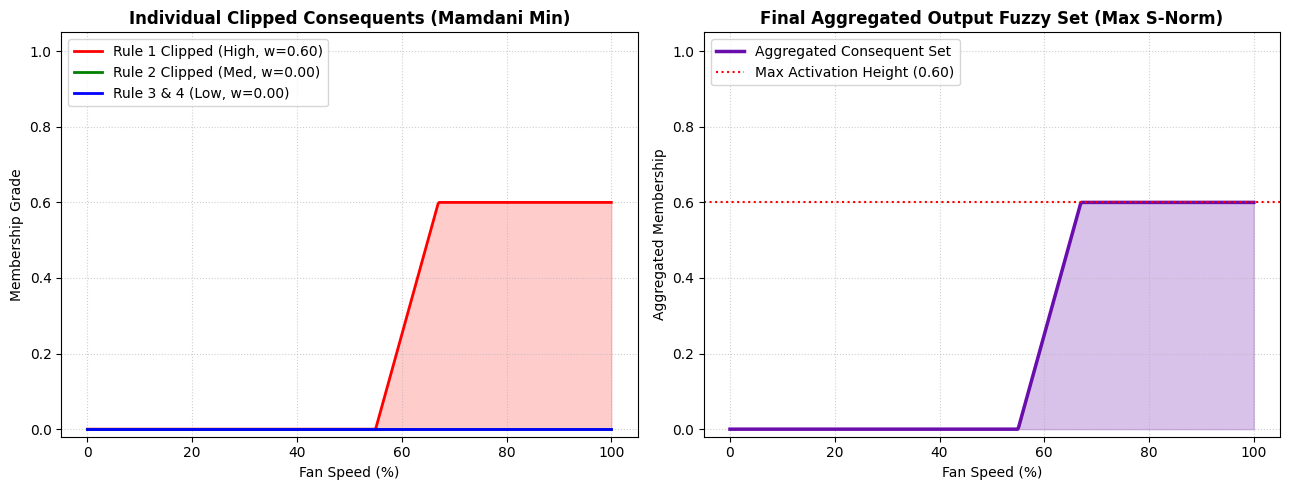

In [3]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Individual Rule Outputs
ax1.plot(fan_univ, out_r1, 'r-', linewidth=2, label=f'Rule 1 Clipped (High, w={w1:.2f})')
ax1.fill_between(fan_univ, out_r1, color='red', alpha=0.2)

ax1.plot(fan_univ, out_r2, 'g-', linewidth=2, label=f'Rule 2 Clipped (Med, w={w2:.2f})')
ax1.fill_between(fan_univ, out_r2, color='green', alpha=0.2)

ax1.plot(fan_univ, out_r3, 'b-', linewidth=2, label=f'Rule 3 & 4 (Low, w={max(w3, w4):.2f})')

ax1.set_title('Individual Clipped Consequents (Mamdani Min)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Fan Speed (%)')
ax1.set_ylabel('Membership Grade')
ax1.set_ylim(-0.02, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left')

# Plot Aggregated Fuzzy Output
ax2.plot(fan_univ, aggregated_fan, color='#6a0dad', linewidth=2.5, label='Aggregated Consequent Set')
ax2.fill_between(fan_univ, aggregated_fan, color='#6a0dad', alpha=0.25)
ax2.axhline(y=w1, color='r', linestyle=':', label=f'Max Activation Height ({w1:.2f})')

ax2.set_title('Final Aggregated Output Fuzzy Set (Max S-Norm)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Fan Speed (%)')
ax2.set_ylabel('Aggregated Membership')
ax2.set_ylim(-0.02, 1.05)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Rule # | Antecedent Condition | Logical Operator | Firing Strength ($w_i$) | Consequent Concluded |
| :---: | :---: | :---: | :---: | :---: |
| **Rule 1** | $\text{Temp}=\text{Hot} \lor \text{Humidity}=\text{Humid}$ | Max (OR) | $w_1 = 0.600$ | Fan High |
| **Rule 2** | $\text{Temp}=\text{Warm} \land \text{Humidity}=\text{Normal}$ | Min (AND) | $w_2 = 0.000$ | Fan Medium |
| **Rule 3** | $\text{Temp}=\text{Cold} \land \text{Humidity}=\text{Dry}$ | Min (AND) | $w_3 = 0.000$ | Fan Low |
| **Rule 4** | $\text{Temp}=\text{Cold} \land \text{Humidity}=\text{Normal}$ | Min (AND) | $w_4 = 0.000$ | Fan Low |

#### Key Observations in Simple Words:
1. **Rule Disjunction (OR):** Rule 1 evaluates to $\max(0.375, 0.600) = 0.600$ because humidity is high ($72\%$), firing high fan speed even though temperature is only moderately hot.
2. **Selective Activation:** Rules 2, 3, and 4 have zero firing strength under these conditions, ensuring that inactive rules contribute nothing to the final decision.
3. **Mamdani Implication:** The output fuzzy set for 'High' is truncated horizontally at $\mu = 0.600$, maintaining the shape of the consequent while bounding its maximum truth value.

---
### 7. Conclusion
1. We designed a multi-input fuzzy IF–THEN rule base for climate decision making.
2. We implemented antecedent evaluation using Min (AND) and Max (OR) fuzzy operators.
3. We demonstrated Mamdani implication clipping and maximum rule aggregation in Python.